# Spotify genre classification

Classification of ten musical genres from audio descriptors and musical metadata. The dataset contains 10,000 tracks, with 1,000 per genre.

**Source:** [Spotify 10000 tracks (genre manually labeled), Adam Wu, Kaggle](https://www.kaggle.com/datasets/adamwu/spotify-10000-tracks-with-genre). Track names, artist names and IDs are excluded from the predictors. Musical key, mode and time signature are categorical inputs.

Model comparison uses training cross-validation. The Random Forest selection rule allows a validation macro-F1 loss of up to 0.04 from the highest tested mean, then chooses the smallest training/validation gap. This balances predictive performance and regularization; the test does not determine the choice.

**Colab:** run all cells and upload `10k_tracks.csv` when prompted. **Local:** keep the CSV beside the notebook or in `data/`.

**Dataset license:** Adam Wu, [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/). The included CSV is unchanged.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import time
import pandas as pd
import numpy as np
from IPython.display import display, Markdown

started = time.perf_counter()
SEED = 42
N_JOBS = 2
DATA_PATH = next((p for p in [Path('data/10k_tracks.csv'), Path('10k_tracks.csv')] if p.is_file()), None)
if DATA_PATH is None:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Place 10k_tracks.csv in data/ and open the project folder.') from None
    files.upload()
    DATA_PATH = Path('10k_tracks.csv')
    if not DATA_PATH.is_file():
        raise FileNotFoundError('Upload the file named 10k_tracks.csv.')

REPORTS = Path('reports')
MODELS = Path('models')
REPORTS.mkdir(exist_ok=True)
MODELS.mkdir(exist_ok=True)
df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
print('Columns:', list(df.columns))
df.head()

Shape: (10000, 17)
Columns: ['trackName', 'artistName', 'genre', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'id', 'duration_ms', 'time_signature']


,trackName,artistName,genre,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,id,duration_ms,time_signature
0,"""In The Hall Of The Mountain King"" from Peer G...",London Symphony Orchestra,Classical,0.475,0.130,7,-17.719,1,0.0510,0.9160,0.956000,0.1010,0.122,112.241,14Qcrx6Dfjvcj0H8oV8oUW,150827,4
1,#BrooklynBloodPop!,SyKo,Electronic/Dance Music,0.691,0.814,1,-3.788,0,0.1170,0.0164,0.000000,0.3660,0.509,132.012,7K9Z3yFNNLv5kwTjQYGjnu,145611,4
2,$10,Good Morning,Pop,0.624,0.596,4,-9.804,1,0.0314,0.4750,0.203000,0.1190,0.896,120.969,3koAwrM1RO0TGMeQJ3qt9J,89509,4
3,(I Just) Died In Your Arms,Cutting Crew,Rock,0.625,0.726,11,-11.402,0,0.0444,0.0158,0.000169,0.0625,0.507,124.945,4ByEFOBuLXpCqvO1kw8Wdm,280400,4
4,"...And to Those I Love, Thanks for Sticking Ar...",$uicideboy$,Rap/Hip Hop,0.792,0.511,2,-6.876,1,0.0409,0.1240,0.000090,0.1400,0.111,113.983,30QR0ndUdiiMQMA9g1PGCm,168490,4


## Schema checks

In this section I:

- Identify the target column (genre)
- Check the number of classes and whether the dataset is balanced
- Check missing values (to decide whether imputation is needed)
- Check duplicates using the id column (to reduce leakage risk)

In [2]:
target_candidates = [c for c in df.columns if 'genre' in c.lower()]
assert target_candidates == ['genre'], 'Expected one genre target'
target = 'genre'
required = ['trackName', 'artistName', 'id', 'genre', 'danceability', 'energy', 'key',
            'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness',
            'liveness', 'valence', 'tempo', 'duration_ms', 'time_signature']
assert set(required).issubset(df.columns), 'Missing expected columns'
assert len(df) == 10000 and df[target].nunique() == 10, 'Unexpected dataset version'
assert df[[target, 'id', 'artistName']].notna().all().all(), 'Missing target/identity'
assert df['id'].is_unique, 'Duplicate IDs need review before splitting'
print('Classes:', df[target].nunique())
print(df[target].value_counts())
print('Missing values:\n', df.isna().sum())
print('Duplicate IDs:', df.duplicated('id').sum())

Classes: 10
genre
Classical                 1000
Electronic/Dance Music    1000
Pop                       1000
Rock                      1000
Rap/Hip Hop               1000
Country                   1000
Folk/International        1000
R&B/Soul                  1000
Jazz/Blues/Fusion         1000
Reggae                    1000
Name: count, dtype: int64
Missing values:
 trackName           0
artistName          0
genre               0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
id                  0
duration_ms         0
time_signature      0
dtype: int64
Duplicate IDs: 0


The dataset is balanced and the supplied CSV has no missing values or repeated IDs.
Imputation is retained inside the pipeline for missing feature values.
Unique IDs do not prove that artist identities or duplicate recordings are independent:
the split below audits artist-credit overlap and repeated audio vectors as limitations.

In [3]:
drop_cols = ['id', 'trackName', 'artistName']
feature_cols = [c for c in required if c not in [target] + drop_cols]
X = df[feature_cols].copy()
y = df[target]
assert all(pd.api.types.is_numeric_dtype(X[c]) for c in X), 'Non-numeric audio field'
assert not np.isinf(X.to_numpy(dtype=float)).any(), 'Infinite feature value'
print('Dropped columns:', drop_cols)
print('X shape:', X.shape)
print('Number of classes:', y.nunique())

Dropped columns: ['id', 'trackName', 'artistName']
X shape: (10000, 13)
Number of classes: 10


## Train/test split

A stratified 80/20 split with seed 42 gives 8,000 training tracks and 2,000 test tracks. Preprocessing and parameter selection use training cross-validation. The selected pipeline is fixed before test evaluation.

The audit below counts shared artist credits and identical audio vectors between the two sets. This track split evaluates classification within the collection; it does not measure generalization to unseen artists.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
assert not set(X_train.index) & set(X_test.index)
assert set(y_train) == set(y_test) and y_train.value_counts().eq(800).all() and y_test.value_counts().eq(200).all()
print('Train size:', X_train.shape, 'Test size:', X_test.shape)
artists = df['artistName'].str.strip().str.casefold()
artist_overlap = float(artists.loc[X_test.index].isin(artists.loc[X_train.index]).mean())
audio_vectors = list(X.itertuples(index=False, name=None))
audio_overlap = len({audio_vectors[i] for i in X_train.index} & {audio_vectors[i] for i in X_test.index})
print(f'Test tracks with an artist credit already in training: {artist_overlap:.2%}')
print('Identical audio vectors shared by training and test:', audio_overlap)
split = pd.Series('train', index=df.index)
split.loc[X_test.index] = 'test'
pd.DataFrame({'track_id': df['id'], 'split': split}).to_csv(REPORTS / 'split_assignments.csv', index=False)

Train size: (8000, 13) Test size: (2000, 13)
Test tracks with an artist credit already in training: 57.55%
Identical audio vectors shared by training and test: 34


## Exploratory Data Analysis (EDA)

Inspect continuous feature distributions, IQR flags and correlations using training data only. Class counts above are a schema audit. An IQR flag is not evidence of an incorrect observation, so tracks are not removed just because they are unusual.

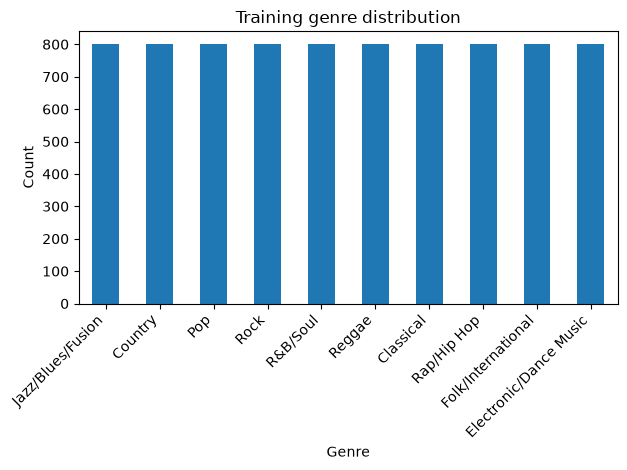

In [5]:
import matplotlib.pyplot as plt

ax = y_train.value_counts().plot(kind="bar")
plt.title("Training genre distribution")
plt.xlabel("Genre")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [6]:
X_train.describe().T[['mean', 'std', 'min', 'max']].round(3)

,mean,std,min,max
danceability,0.578,0.181,0.000,0.970
energy,0.558,0.262,0.001,0.999
key,5.218,3.563,0.000,11.000
loudness,-9.871,7.032,-47.903,1.106
mode,0.631,0.483,0.000,1.000
speechiness,0.086,0.090,0.000,0.883
acousticness,0.359,0.350,0.000,0.996
instrumentalness,0.190,0.340,0.000,0.984
liveness,0.167,0.129,0.019,0.982
valence,0.491,0.263,0.000,1.000


In [7]:
n_unique = X_train.nunique().sort_values()
print(n_unique.head(10))

mode                   2
time_signature         5
key                   12
danceability         899
speechiness         1108
liveness            1173
valence             1250
energy              1434
acousticness        2373
instrumentalness    2697
dtype: int64


### Feature typing

Here I explicitly control feature types to ensure the preprocessing matches the meaning of each feature.

Some features are stored as integers but represent categories rather than continuous quantities (e.g., musical key, time signature and mode).
Treating them as categorical can be more appropriate than scaling them as continuous variables.

In [8]:
# Features that are integers but represent categories
forced_cat = [c for c in ["key", "mode", "time_signature"] if c in X.columns]

# Numeric continuous features
num_cols = [c for c in X.select_dtypes(include=["number"]).columns if c not in forced_cat]

# Categorical columns
cat_cols = forced_cat

print("Numeric cols:", num_cols)
print("Categorical cols:", cat_cols)

Numeric cols: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']
Categorical cols: ['key', 'mode', 'time_signature']


In [9]:
# Quick outlier check
outlier_rates = {}
for col in num_cols:
    q1, q3 = np.percentile(X_train[col], [25, 75])
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    outlier_rates[col] = np.mean((X_train[col] < low) | (X_train[col] > high))

outlier_rates = dict(sorted(outlier_rates.items(), key=lambda x: x[1], reverse=True))
print("Top outlier rates:")
for k, v in list(outlier_rates.items())[:8]:
    print(f"{k:20s} {v:.3f}")

Top outlier rates:
instrumentalness     0.213
speechiness          0.137
loudness             0.087
liveness             0.075
duration_ms          0.056
danceability         0.009
tempo                0.000
energy               0.000


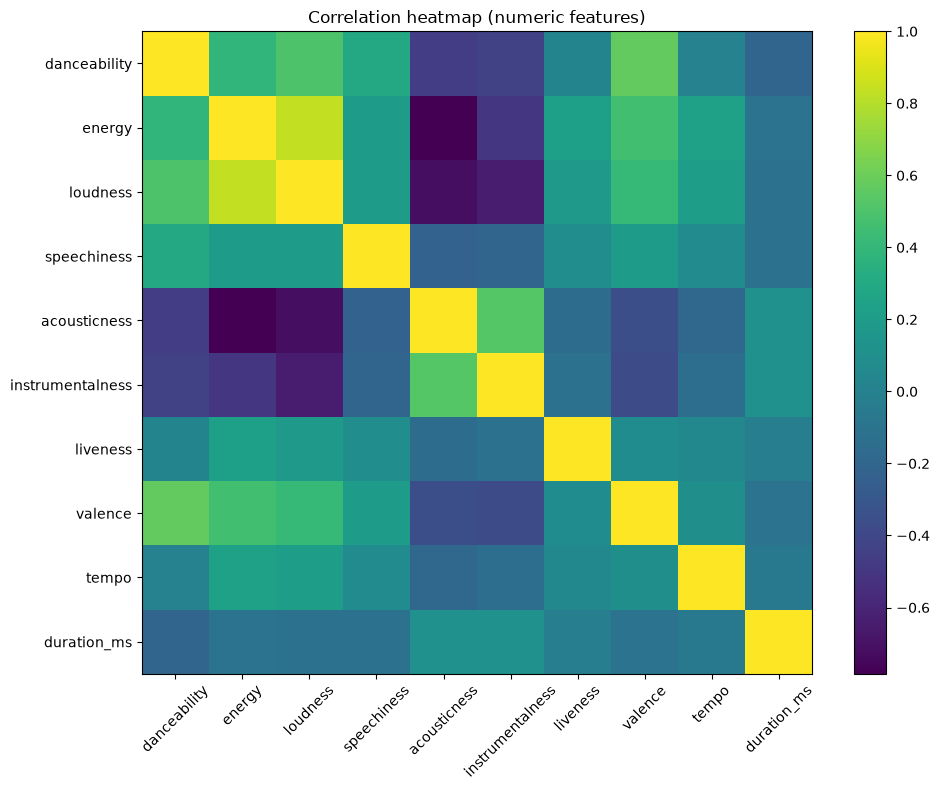

In [10]:
import matplotlib.pyplot as plt

corr = X_train[num_cols].corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, aspect="auto")
plt.colorbar()
plt.title("Correlation heatmap (numeric features)")
plt.xticks(range(len(num_cols)), num_cols, rotation=45)
plt.yticks(range(len(num_cols)), num_cols)
plt.tight_layout()
plt.show()

Continuous inputs have different ranges, so scaling is useful for linear models and KNN. StandardScaler is not automatically robust to outliers. Random Forest does not require scaling; the common pipeline simplifies the comparison. Correlated descriptors may share predictive information.

## Preprocessing pipeline

Use Pipeline and ColumnTransformer: median imputation and standard scaling for continuous variables; most-frequent imputation and one-hot encoding for key, mode and time signature. Each CV fit learns transformations from its training fold, preventing preprocessing leakage into validation.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numeric_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_pipe, num_cols),
        ("cat", categorical_pipe, cat_cols)
    ],
    remainder="drop"
)

In [12]:
print('Continuous inputs:', num_cols)
print('Categorical inputs:', cat_cols)

Continuous inputs: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']
Categorical inputs: ['key', 'mode', 'time_signature']


## Baselines

I use two reference models:

1. **DummyClassifier (uniform):** random guessing baseline.  
   Because the dataset is balanced (10 genres), uniform guessing is a meaningful lower bound.

2. **Logistic Regression (multinomial):** simple, interpretable linear classifier.  
   This is a strong baseline for tabular data and helps check whether the audio features contain a learnable signal.

If a more complex model does not outperform these baselines, its additional complexity is hard to justify.

In [13]:
from sklearn.dummy import DummyClassifier

dummy = Pipeline(steps=[
    ("preprocess", preprocess),
    ("clf", DummyClassifier(strategy="uniform", random_state=42))
])
dummy.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](10,)","['Classical','Country','Electronic/Dance Music',...,'Rap/Hip Hop','Reggae', 'Rock']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['danceability','energy','key',...,'tempo','duration_ms','time_signature']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are d

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import cross_validate, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {'acc': 'accuracy', 'macro_f1': 'f1_macro'}
logreg_no_dr = Pipeline([('preprocess', preprocess), ('clf', LogisticRegression(solver='lbfgs', max_iter=2000))])
logreg_svd = Pipeline([('preprocess', preprocess), ('svd', TruncatedSVD(n_components=20, random_state=SEED)),
                       ('clf', LogisticRegression(solver='lbfgs', max_iter=2000))])

def cv_summary(model, name):
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring,
                            return_train_score=True, n_jobs=N_JOBS, error_score='raise')
    return {'model': name, 'acc_mean': scores['test_acc'].mean(), 'acc_std': scores['test_acc'].std(),
            'macro_f1_mean': scores['test_macro_f1'].mean(), 'macro_f1_std': scores['test_macro_f1'].std(),
            'train_macro_f1': scores['train_macro_f1'].mean(),
            'gap': scores['train_macro_f1'].mean() - scores['test_macro_f1'].mean()}

results = [cv_summary(logreg_no_dr, 'Logistic Regression'), cv_summary(logreg_svd, 'Logistic Regression + SVD')]
display(pd.DataFrame(results).round(4))

,model,acc_mean,acc_std,macro_f1_mean,macro_f1_std,train_macro_f1,gap
0,Logistic Regression,0.4966,0.0136,0.4889,0.0133,0.5032,0.0144
1,Logistic Regression + SVD,0.4930,0.0146,0.4855,0.0145,0.4970,0.0115


The SVD comparison tests whether reducing the encoded feature space helps Logistic Regression. No dimensionality reduction is imposed on the other classifiers. The table reports the measured training-CV scores.

## LinearSVC and regularization

The linear SVM provides another baseline. C controls regularization: larger C penalizes training errors more strongly. Choose C using training CV. The selected search score is a development estimate and can be optimistic after parameter selection; repeating the same folds is not independent validation.

In [15]:
from sklearn.svm import LinearSVC

linsvc = Pipeline(steps=[
    ("preprocess", preprocess),
    ("clf", LinearSVC(max_iter=10000, dual="auto", random_state=SEED))
])

In [16]:
from sklearn.model_selection import GridSearchCV

search_svc = GridSearchCV(linsvc, {'clf__C': [0.01, 0.1, 1.0, 10.0]}, cv=cv, scoring=scoring,
                          refit='macro_f1', return_train_score=True, n_jobs=N_JOBS, error_score='raise')
search_svc.fit(X_train, y_train)

def search_summary(search, name):
    r, i = search.cv_results_, search.best_index_
    return {'model': name, 'acc_mean': r['mean_test_acc'][i], 'acc_std': r['std_test_acc'][i],
            'macro_f1_mean': r['mean_test_macro_f1'][i], 'macro_f1_std': r['std_test_macro_f1'][i],
            'train_macro_f1': r['mean_train_macro_f1'][i],
            'gap': r['mean_train_macro_f1'][i] - r['mean_test_macro_f1'][i]}

print('Selected linear SVM C:', search_svc.best_params_)

Selected linear SVM C: {'clf__C': 10.0}


## Random Forest

Random Forest combines decision trees to capture nonlinear patterns and feature interactions. It uses the same preprocessing pipeline as the other classifiers, although scaling is not required for trees. Limiting depth and increasing leaf size can reduce overfitting; validation scores show the cost of those restrictions.

In [17]:
from sklearn.ensemble import RandomForestClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_model = Pipeline([
    ("preprocess", preprocess),
    ("clf", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=1,
        class_weight=None
    ))
])

## K-nearest neighbors

KNN predicts from nearby training tracks in the scaled and encoded feature space. Compare neighbor counts and uniform versus distance weights using training CV. More neighbors can smooth predictions, potentially at the cost of validation performance. Distance-weighted KNN predicts its own training observations almost perfectly by construction, so that training score requires cautious interpretation.

In [18]:
from sklearn.neighbors import KNeighborsClassifier

knn = Pipeline([('preprocess', preprocess), ('clf', KNeighborsClassifier())])
search_knn = GridSearchCV(knn, {'clf__n_neighbors': [5, 15, 31, 61], 'clf__weights': ['uniform', 'distance']},
                          cv=cv, scoring=scoring, refit='macro_f1', return_train_score=True,
                          n_jobs=N_JOBS, error_score='raise')
search_knn.fit(X_train, y_train)
print('KNN parameters:', search_knn.best_params_)

KNN parameters: {'clf__n_neighbors': 31, 'clf__weights': 'distance'}


## Model comparison

All classifiers use the same five stratified folds. The table reports mean training and validation macro-F1 alongside accuracy. Scores selected through parameter searches are development estimates and may be optimistic. The test set is excluded from this comparison.

In [19]:
cv_results = [cv_summary(dummy, 'Dummy (uniform)'), *results,
              search_summary(search_svc, 'LinearSVC'), cv_summary(rf_model, 'Random Forest (initial)'),
              search_summary(search_knn, 'KNN')]
cv_results_df = pd.DataFrame(cv_results).sort_values('macro_f1_mean', ascending=False)
display(cv_results_df.round(4))

,model,acc_mean,acc_std,macro_f1_mean,macro_f1_std,train_macro_f1,gap
4,Random Forest (initial),0.5659,0.0137,0.5598,0.0128,0.9998,0.4400
5,KNN,0.4965,0.0095,0.4904,0.0101,0.9998,0.5093
1,Logistic Regression,0.4966,0.0136,0.4889,0.0133,0.5032,0.0144
2,Logistic Regression + SVD,0.4930,0.0146,0.4855,0.0145,0.4970,0.0115
3,LinearSVC,0.4751,0.0104,0.4510,0.0112,0.4654,0.0143
0,Dummy (uniform),0.0911,0.0044,0.0909,0.0043,0.1008,0.0098


## Random Forest regularization

The grid compares tree depths, minimum leaf sizes and feature-sampling settings, including a more flexible reference configuration.

Among configurations within 0.04 macro-F1 of the highest validation mean, the selection rule chooses the smallest mean training/validation gap. This tolerance allows stronger regularization while retaining useful validation performance. It is a practical tradeoff, not a significance test. Minimizing the gap without a performance constraint could favor underfitting.

The selected forest is then compared with the other classifiers using training CV, before final test evaluation.

In [20]:
from sklearn.base import clone

rf = Pipeline([('preprocess', preprocess), ('clf', RandomForestClassifier(random_state=SEED, n_jobs=1))])
param_grid = [
    {'clf__n_estimators': [618], 'clf__max_depth': [15], 'clf__min_samples_split': [9],
     'clf__min_samples_leaf': [1], 'clf__max_features': ['sqrt']},
    {'clf__n_estimators': [300], 'clf__max_depth': [8, 12, 16, 20], 'clf__min_samples_split': [9],
     'clf__min_samples_leaf': [2, 4, 8], 'clf__max_features': ['sqrt', 0.5]},
]

def select_rf_config(r):
    means = np.asarray(r['mean_test_macro_f1'])
    eligible = np.flatnonzero(means >= means.max() - 0.04)
    gap = np.asarray(r['mean_train_macro_f1']) - means
    return int(min(eligible, key=lambda i: (gap[i], r['params'][i]['clf__max_depth'],
                                           -r['params'][i]['clf__min_samples_leaf'])))

# A simpler fit may be preferred only if validation remains within the declared tolerance.
toy = {'mean_test_macro_f1': [0.56, 0.558, 0.53], 'mean_train_macro_f1': [0.98, 0.85, 0.60],
       'params': [{'clf__max_depth': 15, 'clf__min_samples_leaf': 1},
                  {'clf__max_depth': 12, 'clf__min_samples_leaf': 4},
                  {'clf__max_depth': 8, 'clf__min_samples_leaf': 8}]}
assert select_rf_config(toy) == 2
search_rf = GridSearchCV(rf, param_grid, cv=cv, scoring=scoring, refit=select_rf_config,
                         return_train_score=True, n_jobs=N_JOBS, error_score='raise')
search_rf.fit(X_train, y_train)
best_rf = search_rf.best_estimator_
rf_search_results = pd.DataFrame(search_rf.cv_results_)
rf_search_results['gap'] = rf_search_results['mean_train_macro_f1'] - rf_search_results['mean_test_macro_f1']
rf_search_results.to_csv(REPORTS / 'rf_search.csv', index=False)
print('Final RF parameters:', search_rf.best_params_)
display(rf_search_results[['params', 'mean_train_macro_f1', 'mean_test_macro_f1', 'gap']]
        .sort_values('mean_test_macro_f1', ascending=False).head(8))
print('Smallest-gap RF configuration (may sacrifice validation performance):')
display(rf_search_results[['params', 'mean_train_macro_f1', 'mean_test_macro_f1', 'gap']].sort_values('gap').head(1))

final_candidates = pd.DataFrame([results[0], results[1], search_summary(search_svc, 'LinearSVC'),
                                search_summary(search_knn, 'KNN'), search_summary(search_rf, 'Random Forest')])
final_candidates = final_candidates.sort_values('macro_f1_mean', ascending=False)
final_candidates.to_csv(REPORTS / 'model_comparison.csv', index=False)
display(final_candidates.round(4))
final_model_name = final_candidates.iloc[0]['model']
model_lookup = {'Logistic Regression': logreg_no_dr, 'Logistic Regression + SVD': logreg_svd,
                'LinearSVC': search_svc.best_estimator_, 'KNN': search_knn.best_estimator_, 'Random Forest': best_rf}
final_model = clone(model_lookup[final_model_name]).fit(X_train, y_train)
print('Selected model:', final_model_name)

Final RF parameters: {'clf__max_depth': 8, 'clf__max_features': 0.5, 'clf__min_samples_leaf': 8, 'clf__min_samples_split': 9, 'clf__n_estimators': 300}


,params,mean_train_macro_f1,mean_test_macro_f1,gap
19,"{'clf__max_depth': 20, 'clf__max_features': 's...",0.937465,0.563424,0.374041
0,"{'clf__max_depth': 15, 'clf__max_features': 's...",0.927535,0.561932,0.365603
20,"{'clf__max_depth': 20, 'clf__max_features': 's...",0.890749,0.560026,0.330723
13,"{'clf__max_depth': 16, 'clf__max_features': 's...",0.917501,0.559559,0.357942
16,"{'clf__max_depth': 16, 'clf__max_features': 0....",0.925562,0.558774,0.366789
14,"{'clf__max_depth': 16, 'clf__max_features': 's...",0.873866,0.558018,0.315847
22,"{'clf__max_depth': 20, 'clf__max_features': 0....",0.939138,0.557159,0.381979
23,"{'clf__max_depth': 20, 'clf__max_features': 0....",0.895384,0.555084,0.340300


Smallest-gap RF configuration (may sacrifice validation performance):


,params,mean_train_macro_f1,mean_test_macro_f1,gap
6,"{'clf__max_depth': 8, 'clf__max_features': 0.5...",0.625331,0.528757,0.096574


,model,acc_mean,acc_std,macro_f1_mean,macro_f1_std,train_macro_f1,gap
4,Random Forest,0.5354,0.0129,0.5288,0.0133,0.6253,0.0966
3,KNN,0.4965,0.0095,0.4904,0.0101,0.9998,0.5093
0,Logistic Regression,0.4966,0.0136,0.4889,0.0133,0.5032,0.0144
1,Logistic Regression + SVD,0.4930,0.0146,0.4855,0.0145,0.4970,0.0115
2,LinearSVC,0.4751,0.0104,0.4510,0.0112,0.4654,0.0143


Selected model: Random Forest


## Final test evaluation

The fixed model is evaluated on the 2,000 test tracks using accuracy, macro-F1, weighted-F1 and per-class precision and recall. The following error analysis and feature-importance results describe the model; they are not used for retuning.

In [21]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

y_pred = final_model.predict(X_test)
metrics = {'accuracy': float(accuracy_score(y_test, y_pred)),
           'macro_f1': float(f1_score(y_test, y_pred, average='macro')),
           'weighted_f1': float(f1_score(y_test, y_pred, average='weighted'))}
print('FINAL TEST RESULTS:', final_model_name)
print(metrics)
print(classification_report(y_test, y_pred, zero_division=0))
pd.DataFrame(classification_report(y_test, y_pred, output_dict=True, zero_division=0)).T.to_csv(REPORTS / 'classification_report.csv')
pd.DataFrame({'track_id': df.loc[X_test.index, 'id'], 'true_genre': y_test, 'predicted_genre': y_pred}).to_csv(REPORTS / 'test_predictions.csv', index=False)
(REPORTS / 'test_metrics.json').write_text(json.dumps(metrics, indent=2) + '\n')

FINAL TEST RESULTS: Random Forest
{'accuracy': 0.522, 'macro_f1': 0.5145169762376973, 'weighted_f1': 0.5145169762376973}
                        precision    recall  f1-score   support

             Classical       0.81      0.90      0.86       200
               Country       0.47      0.57      0.52       200
Electronic/Dance Music       0.52      0.47      0.49       200
    Folk/International       0.48      0.34      0.39       200
     Jazz/Blues/Fusion       0.52      0.59      0.55       200
                   Pop       0.38      0.34      0.36       200
              R&B/Soul       0.38      0.30      0.34       200
           Rap/Hip Hop       0.52      0.56      0.54       200
                Reggae       0.56      0.66      0.60       200
                  Rock       0.51      0.48      0.49       200

              accuracy                           0.52      2000
             macro avg       0.51      0.52      0.51      2000
          weighted avg       0.51      0.52  

95

## Error analysis (confusion matrix + common confusions)

I use the confusion matrix to understand:
- which genres are recognized well
- which genres are often confused

I also extract the most frequent misclassifications (“top confusions”) to discuss why some genres are harder to separate using audio features.

In [22]:
from sklearn.metrics import confusion_matrix

labels = np.sort(y_test.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)

cm_norm = cm / cm.sum(axis=1, keepdims=True)
cm_norm_df = pd.DataFrame(cm_norm, index=labels, columns=labels)
cm_norm_df

,Classical,Country,Electronic/Dance Music,Folk/International,Jazz/Blues/Fusion,Pop,R&B/Soul,Rap/Hip Hop,Reggae,Rock
Classical,0.900,0.000,0.000,0.035,0.065,0.000,0.000,0.000,0.000,0.000
Country,0.000,0.575,0.050,0.035,0.015,0.090,0.065,0.035,0.025,0.110
Electronic/Dance Music,0.000,0.110,0.470,0.025,0.020,0.100,0.025,0.090,0.035,0.125
Folk/International,0.095,0.025,0.015,0.335,0.270,0.055,0.095,0.010,0.060,0.040
Jazz/Blues/Fusion,0.085,0.015,0.010,0.135,0.590,0.040,0.045,0.005,0.015,0.060
Pop,0.015,0.165,0.075,0.050,0.045,0.345,0.035,0.105,0.105,0.060
R&B/Soul,0.000,0.075,0.060,0.035,0.075,0.095,0.300,0.160,0.140,0.060
Rap/Hip Hop,0.005,0.020,0.095,0.005,0.000,0.120,0.055,0.565,0.125,0.010
Reggae,0.000,0.040,0.005,0.015,0.025,0.040,0.120,0.090,0.655,0.010
Rock,0.005,0.195,0.120,0.035,0.040,0.030,0.045,0.025,0.020,0.485


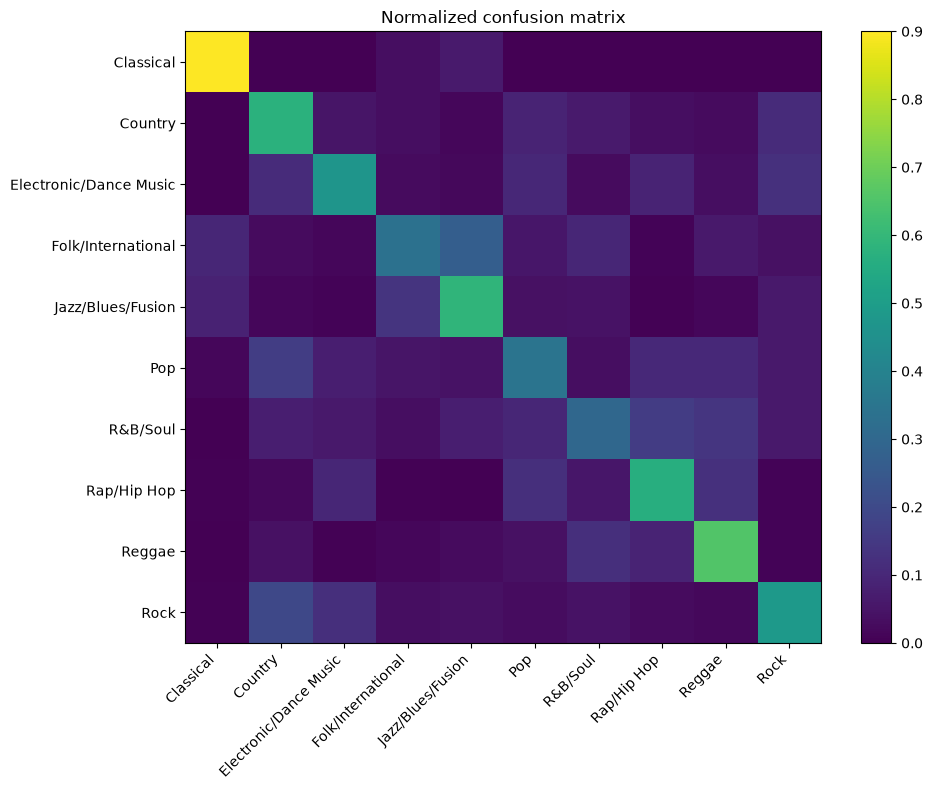

In [23]:
plt.figure(figsize=(10, 8))
plt.imshow(cm_norm, aspect="auto")
plt.colorbar()
plt.title("Normalized confusion matrix")
plt.xticks(range(len(labels)), labels, rotation=45, ha="right")
plt.yticks(range(len(labels)), labels)
plt.tight_layout()
plt.savefig(REPORTS / 'confusion_matrix.png', bbox_inches='tight')
plt.show()

Next, I examine the **most frequent off-diagonal confusions**.
These confusions are expected when genres share similar audio characteristics (e.g., tempo, energy, danceability, acousticness).

In [24]:
cm_off = cm.copy()
#  set the diagonal to 0, so you ignore correct predictions and keep only errors
np.fill_diagonal(cm_off, 0) 

pairs = []
for i, true_lab in enumerate(labels):
    for j, pred_lab in enumerate(labels):
        if cm_off[i, j] > 0:
            pairs.append((true_lab, pred_lab, cm_off[i, j]))

# sort the errors by count and show the top 10 most frequent confusions
top_confusions = (pd.DataFrame(pairs, columns=["true", "pred", "count"])
                  .sort_values("count", ascending=False)
                  .head(10))
top_confusions

,true,pred,count
21,Folk/International,Jazz/Blues/Fusion,54
70,Rock,Country,39
37,Pop,Country,33
50,R&B/Soul,Rap/Hip Hop,32
51,R&B/Soul,Reggae,28
30,Jazz/Blues/Fusion,Folk/International,27
59,Rap/Hip Hop,Reggae,25
17,Electronic/Dance Music,Rock,25
71,Rock,Electronic/Dance Music,24
57,Rap/Hip Hop,Pop,24


## Permutation importance

Shuffle each original feature and measure the drop in test macro-F1 for the fixed model.
This is descriptive predictive importance, not a causal explanation. Correlated inputs may
share importance, and a near-zero value does not prove a feature is useless. No feature removal
or tuning uses these test diagnostics.

In [25]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    final_model, X_test, y_test,
    scoring="f1_macro",
    n_repeats=5,
    random_state=42,
    n_jobs=N_JOBS
)

imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
imp.head(15)
imp.to_csv(REPORTS / 'permutation_importance.csv', header=['macro_f1_drop'])
display(imp)

instrumentalness    0.081519
valence             0.074966
danceability        0.071392
speechiness         0.068730
acousticness        0.055288
loudness            0.054094
duration_ms         0.046814
energy              0.026447
tempo               0.014195
mode                0.001851
liveness            0.000584
time_signature      0.000095
key                -0.000144
dtype: float64

Importance reflects how the selected model uses these descriptors in this collection.
Musical interpretations are plausible hypotheses; the plot cannot establish the reason a genre
label was assigned or prove that a particular audio property causes the genre.

## Learning curve

A learning curve compares training and validation macro-F1 at increasing training sizes. Low scores on both may suggest underfitting; a persistent gap suggests the model fits its training examples much better than unseen tracks. A rising validation curve motivates testing more data, while a plateau does not establish a hard performance ceiling.

The curve uses only the training set, with shuffled subsets and five-fold cross-validation.


/Users/danie/.codex/.chatgpt-projects/g-p-6a73a89e2f54819196b627835e7ef77a/deliverables/spotify-genre-classification/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


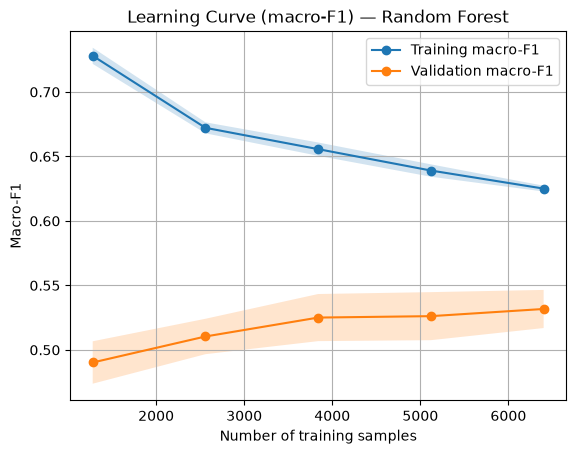

In [26]:
from sklearn.model_selection import learning_curve

rf_for_curve = final_model
cv_lc = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

train_sizes, train_scores, val_scores = learning_curve(
    estimator=rf_for_curve,
    X=X_train,
    y=y_train,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=cv_lc,
    scoring="f1_macro",
    shuffle=True, random_state=SEED, n_jobs=N_JOBS, error_score="raise"
)

train_mean = train_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
val_mean   = val_scores.mean(axis=1)
val_std    = val_scores.std(axis=1)

plt.figure()
plt.title(f"Learning Curve (macro-F1) — {final_model_name}")
plt.xlabel("Number of training samples")
plt.ylabel("Macro-F1")
plt.plot(train_sizes, train_mean, marker="o", label="Training macro-F1")
plt.fill_between(train_sizes, train_mean-train_std, train_mean+train_std, alpha=0.2)
plt.plot(train_sizes, val_mean, marker="o", label="Validation macro-F1")
plt.fill_between(train_sizes, val_mean-val_std, val_mean+val_std, alpha=0.2)
plt.legend()
plt.grid(True)
plt.savefig(REPORTS / 'learning_curve.png', bbox_inches='tight')
plt.show()
pd.DataFrame({'training_rows': train_sizes, 'train_macro_f1': train_mean, 'validation_macro_f1': val_mean}).to_csv(REPORTS / 'learning_curve.csv', index=False)

Training macro-F1 decreases as the sample grows, while validation macro-F1 rises. At the largest training size the gap is about 0.10. Regularization reduces overfitting, but does not eliminate it. These curves use training CV and are development diagnostics; they do not guarantee that more data or further regularization would improve performance.

## Validation curve

A validation curve shows how performance changes when we vary **one hyperparameter** while keeping the rest fixed.

Here I vary **max_depth**

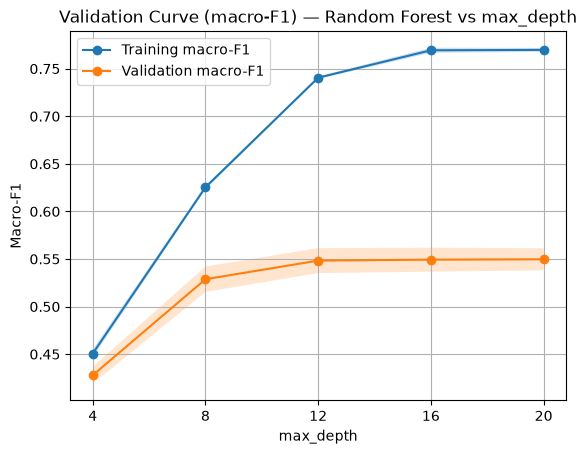

In [27]:
from sklearn.model_selection import validation_curve

rf_for_curve = best_rf
cv_vc = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# max_depth values
param_range = [4, 8, 12, 16, 20]

train_scores, val_scores = validation_curve(
    estimator=rf_for_curve,
    X=X_train,
    y=y_train,
    param_name="clf__max_depth",
    param_range=param_range,
    cv=cv_vc,
    scoring="f1_macro",
    n_jobs=N_JOBS, error_score="raise"
)

train_mean = train_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
val_mean   = val_scores.mean(axis=1)
val_std    = val_scores.std(axis=1)

x = np.arange(len(param_range))

plt.figure()
plt.title("Validation Curve (macro-F1) — Random Forest vs max_depth")
plt.xlabel("max_depth")
plt.ylabel("Macro-F1")
plt.plot(x, train_mean, marker="o", label="Training macro-F1")
plt.fill_between(x, train_mean-train_std, train_mean+train_std, alpha=0.2)
plt.plot(x, val_mean, marker="o", label="Validation macro-F1")
plt.fill_between(x, val_mean-val_std, val_mean+val_std, alpha=0.2)
plt.xticks(x, [str(v) for v in param_range])
plt.legend()
plt.grid(True)
plt.savefig(REPORTS / 'validation_curve.png', bbox_inches='tight')
plt.show()

The RF depth curve is a training-only diagnostic. Shallow trees can underfit; deeper trees can improve validation while also fitting training observations more closely. Interpret both scores together. The plot does not change the model after test evaluation.

## Conclusions

The selected Random Forest reaches validation macro-F1 0.5288 with a training/validation gap of 0.0966. Its test accuracy is 52.20% and test macro-F1 is 0.5145. The smaller gap comes with a loss of validation performance relative to the more flexible configurations.

The main limitations are manually assigned genre labels, summary audio descriptors and shared artists and audio vectors across the track split. Scores used for parameter selection may be optimistic. External validation would be needed to assess performance beyond this collection.

In [28]:
import joblib
import shutil

model_path = MODELS / 'spotify_genre_pipeline.joblib'
joblib.dump(final_model, model_path)
loaded_model = joblib.load(model_path)
assert np.array_equal(loaded_model.predict(X_test), y_pred), 'Reload changed predictions'
selected_row = final_candidates.iloc[0]
metadata = {'selected_model': final_model_name, 'test_metrics': metrics,
            'selected_cv_macro_f1': float(selected_row['macro_f1_mean']),
            'selected_cv_train_macro_f1': float(selected_row['train_macro_f1']),
            'selected_cv_gap': float(selected_row['gap']),
            'rf_params': search_rf.best_params_, 'knn_params': search_knn.best_params_,
            'features': feature_cols, 'seed': SEED,
            'dataset_sha256': hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
            'artist_overlap_fraction': artist_overlap, 'shared_audio_vectors': audio_overlap,
            'protocol': '80/20 stratified track split; training-only five-fold CV searches; regularization tolerance 0.04 macro-F1; internal test',
            'versions': {name: importlib.metadata.version(name) for name in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'joblib']},
            'runtime_seconds': round(time.perf_counter() - started, 1)}
(REPORTS / 'run_metadata.json').write_text(json.dumps(metadata, indent=2) + '\n')
display(Markdown(f"**Selected model:** {final_model_name}. Training-CV macro-F1 "
                 f"{selected_row['macro_f1_mean']:.3f}, training fit {selected_row['train_macro_f1']:.3f}, "
                 f"gap {selected_row['gap']:.3f}. Test accuracy {metrics['accuracy']:.3f}, "
                 f"macro-F1 {metrics['macro_f1']:.3f}. The reduced gap is interpreted together with validation performance and the split limitations."))
print('Saved pipeline, reports and metadata. Runtime:', metadata['runtime_seconds'], 'seconds')
shutil.make_archive('spotify_results', 'zip', REPORTS)

**Selected model:** Random Forest. Training-CV macro-F1 0.529, training fit 0.625, gap 0.097. Test accuracy 0.522, macro-F1 0.515. The reduced gap is interpreted together with validation performance and the split limitations.

Saved pipeline, reports and metadata. Runtime: 362.4 seconds


'/Users/danie/.codex/.chatgpt-projects/g-p-6a73a89e2f54819196b627835e7ef77a/deliverables/spotify-genre-classification-cv/spotify_results.zip'

### Save your work in Colab
Use **File → Download → Download .ipynb** to save the notebook with outputs. In the Files sidebar download `spotify_results.zip` and, if needed, `models/spotify_genre_pipeline.joblib`. Files uploaded to a Colab runtime are temporary. Load only trusted joblib files.
